In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn import __version__ as sk_version

print(f'NumPy:       {np.__version__}')
print(f'Pandas:      {pd.__version__}')
print(f'Scikit-learn:{sk_version}')
print('All libraries imported successfully!')

NumPy:       2.4.6
Pandas:      3.0.6
Scikit-learn:1.9.1
All libraries imported successfully!


In [ ]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


: 

: 

In [ ]:
print("Shape:", df.shape)

print("\nColumn types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

df.describe()

Shape: (20640, 9)

Column types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


: 

: 

# PART 2 — Exploratory Data Analysis  

**2.1  Dataset Overview**

**1. How many instances(mẫu) and features does the dataset contain?**

Bộ dữ liệu California Housing có 20.640 mẫu và 8 đặc trưng đầu vào.
DataFrame có tổng cộng 9 cột, gồm 8 cột đặc trưng và 1 cột mục tiêu là MedHouseVal (giá nhà trung vị).

**2. Are there any missing values? If yes, which features are affected?**

Bộ dữ liệu không có giá trị thiếu. Số lượng giá trị thiếu ở tất cả các cột đều bằng 0.

**3. What is the range of MedInc (median income) in the dataset??**

MedInc có giá trị nhỏ nhất là 0.4999 và giá trị lớn nhất là 15.0001.
Do đó, khoảng giá trị của MedInc là từ 0.4999 đến 15.0001.

**2.2  Visualizations**

**Biểu đồ 1: Phân bố giá nhà MedHouseVal**

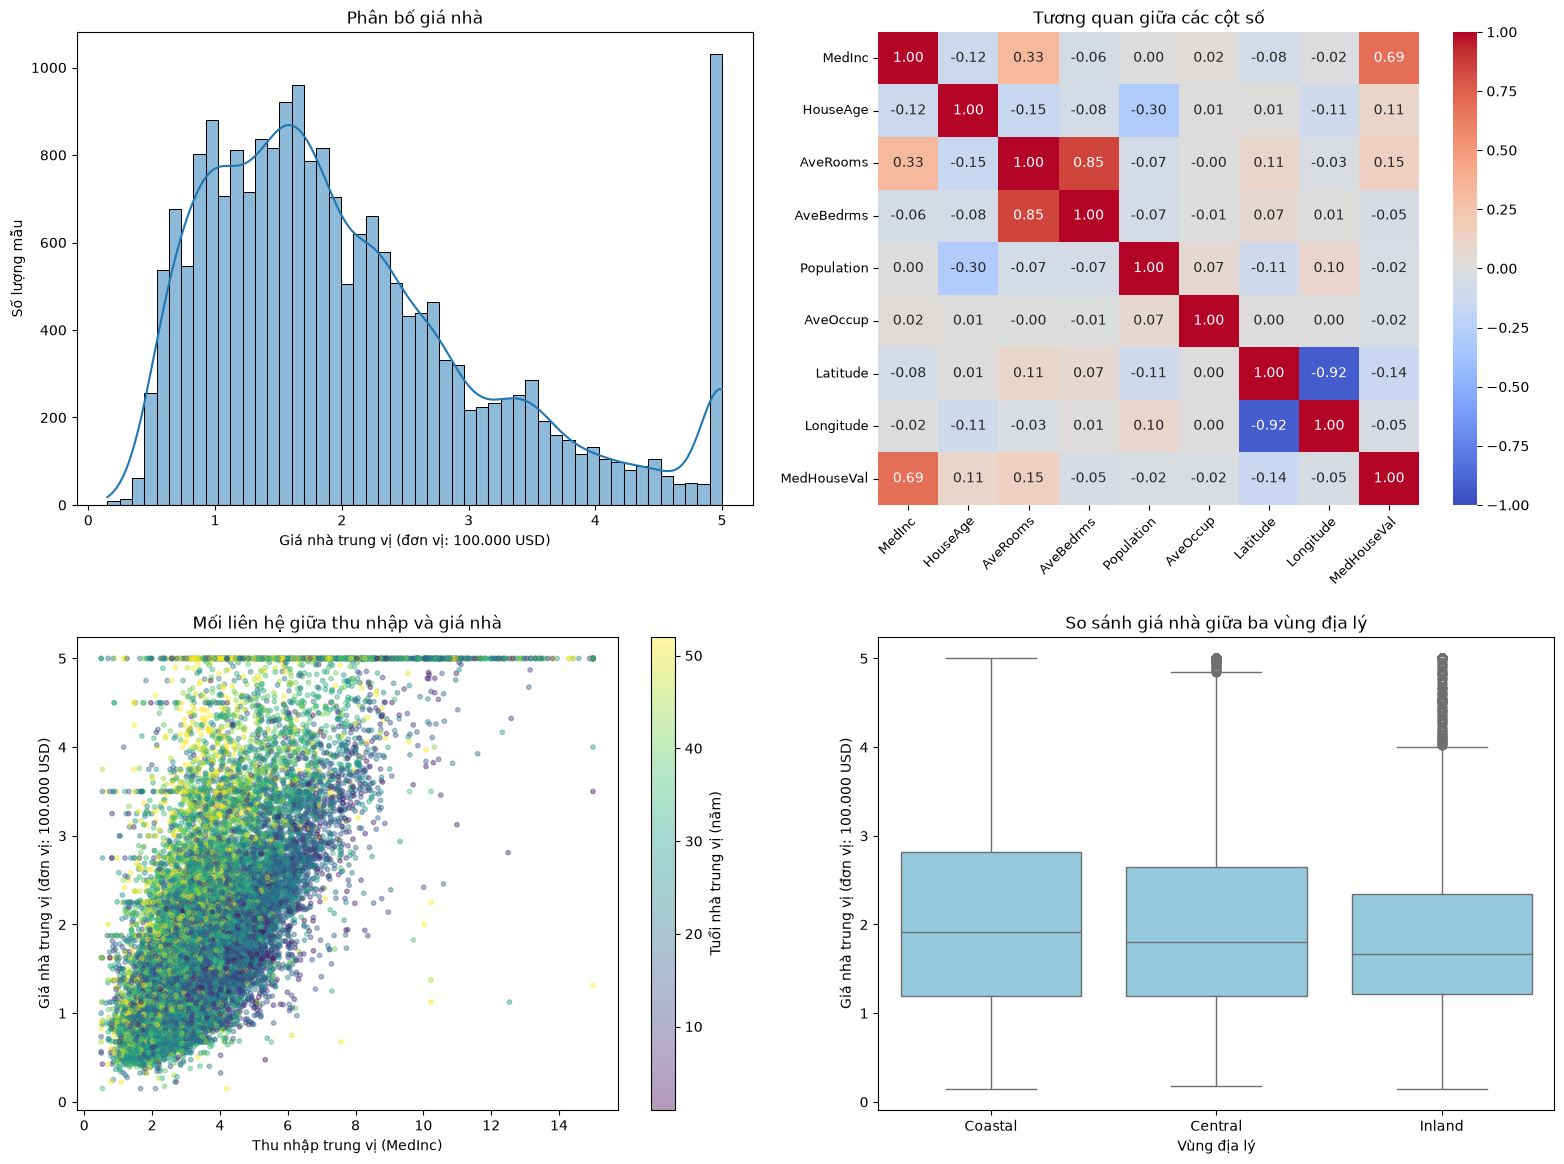

: 

: 

In [ ]:
# Tạo bố cục 2 hàng × 2 cột cho 4 biểu đồ của phần 2.2
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Biểu đồ 1: Histogram kết hợp KDE của giá nhà
sns.histplot(
    data=df,
    x="MedHouseVal",
    bins=50,
    kde=True,
    ax=axes[0, 0]
)

axes[0, 0].set_title("Phân bố giá nhà")
axes[0, 0].set_xlabel("Giá nhà trung vị (đơn vị: 100.000 USD)")
axes[0, 0].set_ylabel("Số lượng mẫu")



# Biểu đồ 2: Heatmap tương quan giữa các cột số
corr_matrix = df.select_dtypes(include="number").corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Tương quan giữa các cột số")

# Xoay nhãn cột để dễ đọc và tránh chen chúc
plt.setp(
    axes[0, 1].get_xticklabels(),
    rotation=45,
    ha="right",
    rotation_mode="anchor",
    fontsize=9
)
axes[0, 1].tick_params(axis="y", labelrotation=0, labelsize=9)


# Biểu đồ 3: Thu nhập và giá nhà, màu thể hiện tuổi nhà
scatter = axes[1, 0].scatter(
    df["MedInc"],
    df["MedHouseVal"],
    c=df["HouseAge"],
    cmap="viridis",
    s=10,
    alpha=0.4
)

axes[1, 0].set_title("Mối liên hệ giữa thu nhập và giá nhà")
axes[1, 0].set_xlabel("Thu nhập trung vị (MedInc)")
axes[1, 0].set_ylabel("Giá nhà trung vị (đơn vị: 100.000 USD)")

# Thêm thanh màu để đọc tuổi nhà
fig.colorbar(
    scatter,
    ax=axes[1, 0],
    label="Tuổi nhà trung vị (năm)"
)


# Biểu đồ 4: So sánh giá nhà giữa ba vùng địa lý
# Tạo bản sao để thêm cột phân vùng phục vụ biểu đồ
df_plot = df.copy()

df_plot["Region"] = np.select(
    [
        df_plot["Longitude"] < -121,
        df_plot["Longitude"] > -118
    ],
    [
        "Coastal",
        "Inland"
    ],
    default="Central"
)

sns.boxplot(
    data=df_plot,
    x="Region",
    y="MedHouseVal",
    order=["Coastal", "Central", "Inland"],
    color="skyblue",
    ax=axes[1, 1]
)

axes[1, 1].set_title("So sánh giá nhà giữa ba vùng địa lý")
axes[1, 1].set_xlabel("Vùng địa lý")
axes[1, 1].set_ylabel("Giá nhà trung vị (đơn vị: 100.000 USD)")


plt.tight_layout(pad=2.0)
plt.savefig('eda_plots.png', dpi=120, bbox_inches='tight')
plt.show()

**Nhận xét biểu đồ 1 — Phân bố giá nhà:**

Phân bố giá nhà lệch phải, với phần lớn các mẫu tập trung trong khoảng 0.5–2.5 đơn vị, tương ứng khoảng 50.000–250.000 USD, trong khi các mức giá cao hơn xuất hiện ít hơn.

Ở mức gần 5 đơn vị, tương ứng khoảng 500.000 USD, xuất hiện một cột có tần suất tăng đột biến so với các khoảng giá liền trước, cho thấy nhiều mẫu tập trung tại mức giá này và cần được lưu ý khi phân tích.

**Nhận xét biểu đồ 2 — Heatmap tương quan:**

MedInc có tương quan dương mạnh nhất với MedHouseVal trong các đặc trưng đầu vào, với hệ số khoảng 0.69, cho thấy các khu vực có thu nhập trung vị cao hơn thường có giá nhà trung vị cao hơn.

Giữa các đặc trưng, AveRooms và AveBedrms có tương quan dương mạnh khoảng 0.85, còn Latitude và Longitude có tương quan âm mạnh khoảng -0.92, cho thấy các cặp biến này có mối liên hệ tuyến tính đáng kể.

**Nhận xét biểu đồ 3 — Mối liên hệ giữa thu nhập và giá nhà:**

Các điểm dữ liệu có xu hướng đi lên khi MedInc tăng, cho thấy những khu vực có thu nhập trung vị cao hơn thường có giá nhà trung vị cao hơn, dù giá nhà vẫn phân tán khá rộng ở cùng một mức thu nhập.

Màu sắc thể hiện HouseAge đan xen ở nhiều mức giá, cho thấy tuổi nhà chưa tạo ra sự phân tách rõ ràng về giá nhà trên biểu đồ này.

**Nhận xét biểu đồ 4 — So sánh giá nhà giữa ba vùng địa lý:**

Theo cách phân vùng của đề, vùng Coastal có trung vị của MedHouseVal cao nhất, tiếp đến là Central và thấp nhất là Inland, cho thấy giá nhà có sự khác biệt giữa ba nhóm địa lý.

Vùng Coastal có khoảng tứ phân vị rộng nhất, thể hiện mức phân tán lớn hơn của 50% giá trị ở giữa, trong khi vùng Inland có nhiều điểm ngoại lệ ở phía giá cao dù trung vị thấp hơn hai vùng còn lại.

**2.3 Phân tích tương quan của các đặc trưng**

Xác định ba đặc trưng có độ tương quan tuyệt đối cao nhất với MedHouseVal và giải thích ý nghĩa của chúng.

In [ ]:
# Tính tương quan có dấu với biến mục tiêu
signed_correlations = df[housing.feature_names + ["MedHouseVal"]].corr()["MedHouseVal"].drop("MedHouseVal")

# Xếp hạng theo độ lớn tuyệt đối của hệ số tương quan
correlations = signed_correlations.abs().sort_values(ascending=False)
print("5 đặc trưng có độ tương quan tuyệt đối cao nhất:")
print(correlations.head(5).round(6))

# Giữ cả dấu để giải thích chiều liên hệ của 3 đặc trưng đứng đầu
top3_features = correlations.head(3).index
top3_correlations = pd.DataFrame({
    "He so tuong quan": signed_correlations.loc[top3_features],
    "Gia tri tuyet doi": correlations.loc[top3_features]
})
print("\n3 đặc trưng được chọn:")
print(top3_correlations.round(6))


5 đặc trưng có độ tương quan tuyệt đối cao nhất:
MedInc       0.688075
AveRooms     0.151948
Latitude     0.144160
HouseAge     0.105623
AveBedrms    0.046701
Name: MedHouseVal, dtype: float64

3 đặc trưng được chọn:
          He so tuong quan  Gia tri tuyet doi
MedInc            0.688075           0.688075
AveRooms          0.151948           0.151948
Latitude         -0.144160           0.144160


: 

: 

**Ba đặc trưng có tương quan mạnh nhất và giải thích:**

1. **MedInc — Thu nhập trung vị (r ≈ 0.6881):** Đây là đặc trưng có tương quan dương mạnh nhất với MedHouseVal. Khu vực có thu nhập cao thường có khả năng chi trả cho nhà ở cao hơn và có thể đi kèm tiện ích, điều kiện sống tốt hơn, nên thu nhập có thể cung cấp thông tin hữu ích để dự đoán giá nhà.

2. **AveRooms — Số phòng trung bình trên mỗi hộ gia đình (r ≈ 0.1519):** Đặc trưng này có tương quan dương yếu với MedHouseVal. Số phòng trung bình cao hơn có thể phản ánh nhà ở rộng hơn hoặc có nhiều không gian sử dụng hơn, vì vậy có thể liên quan đến giá nhà cao hơn; tuy nhiên, đây chỉ là một chỉ báo gián tiếp và mức tương quan tuyến tính còn yếu.

3. **Latitude — Vĩ độ (r ≈ -0.1442):** Đặc trưng này có tương quan âm yếu với MedHouseVal trong bộ dữ liệu. Vĩ độ biểu thị vị trí theo hướng Bắc–Nam và có thể phản ánh khác biệt về thị trường nhà ở, việc làm và tiện ích giữa các khu vực, nên có thể hỗ trợ dự đoán giá nhà khi kết hợp với kinh độ và các đặc trưng khác.

**Lưu ý:** Thứ hạng được xác định theo giá trị tuyệt đối của hệ số tương quan, còn dấu của hệ số cho biết chiều liên hệ. Tương quan không chứng minh quan hệ nhân quả; AveRooms và Latitude nằm trong ba đặc trưng đứng đầu nhưng vẫn có tương quan tuyến tính yếu với giá nhà.


# PART 3 — Data Preprocessing Pipeline

**3.1 Train / Test Split**

**Bước 1: Tạo nhóm thu nhập**

Chia `MedInc` thành 5 nhóm bằng `pd.cut()`: (0, 1.5], (1.5, 3.0], (3.0, 4.5], (4.5, 6.0] và (6.0, +∞). Cột tạm `income_cat` sẽ được dùng để chia train/test theo phân tầng, giúp giữ tỷ lệ các nhóm thu nhập gần giống nhau trong hai tập.


In [ ]:
# Tạo 5 nhóm thu nhập để chuẩn bị chia train/test theo phân tầng
df["income_cat"] = pd.cut(
    df["MedInc"],
    bins=[0, 1.5, 3.0, 4.5, 6.0, float("inf")],
    labels=[1, 2, 3, 4, 5]
)

# Kiểm tra nhóm thu nhập của 5 mẫu đầu tiên
income_preview = df[["MedInc", "income_cat"]].head().copy()
income_preview.index = range(1, len(income_preview) + 1)
income_preview


,MedInc,income_cat
1,8.3252,5
2,8.3014,5
3,7.2574,5
4,5.6431,4
5,3.8462,3


: 

: 

### Bước 2: Chia train/test theo phân tầng

Dùng 80% dữ liệu để huấn luyện và 20% để kiểm tra. Tham số `stratify=df["income_cat"]` giúp giữ tỷ lệ của từng nhóm thu nhập trong hai tập gần giống dữ liệu ban đầu; `random_state=42` giúp tái lập kết quả chia khi chạy lại với cùng dữ liệu.

Sau khi chia, xóa cột tạm `income_cat` khỏi cả hai tập và in số mẫu. Cột gốc `MedInc` vẫn được giữ lại để dùng làm đặc trưng đầu vào.


In [ ]:
from sklearn.model_selection import train_test_split

# Chia 80% train và 20% test, phân tầng theo nhóm thu nhập
train_set, test_set = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["income_cat"]
)

# Xóa cột chỉ dùng để phân tầng khỏi hai tập dữ liệu
train_set = train_set.drop(columns=["income_cat"])
test_set = test_set.drop(columns=["income_cat"])

print(f"Training set: {len(train_set)} samples")
print(f"Test set:     {len(test_set)} samples")


Training set: 16512 samples
Test set:     4128 samples


: 

: 

**Vì sao nên dùng chia phân tầng thay vì chia ngẫu nhiên thông thường ở đây?**

Ở Part 2, `MedInc` có tương quan dương mạnh nhất với giá nhà `MedHouseVal` trong các đặc trưng đầu vào (khoảng 0.69). Vì vậy, thành phần các nhóm thu nhập có thể ảnh hưởng đến kết quả học và đánh giá mô hình.

Chia phân tầng theo `income_cat` giúp tỷ lệ của từng nhóm thu nhập trong train và test gần giống dữ liệu ban đầu, giảm nguy cơ một nhóm có quá nhiều hoặc quá ít mẫu trong tập test do ngẫu nhiên. Chia ngẫu nhiên thông thường có thể cho tỷ lệ gần giống, nhưng không chủ động giữ tỷ lệ của từng nhóm như cách chia phân tầng.

Tỷ lệ **80% train / 20% test** là tỷ lệ chia tổng số mẫu theo yêu cầu của đề. Nó không có nghĩa mỗi nhóm thu nhập chiếm 20% dữ liệu: mỗi nhóm có tỷ lệ riêng và phép chia phân tầng cố gắng giữ tỷ lệ đó trong cả hai tập.

**Kết quả:** Từ 20.640 mẫu, thu được **16.512 mẫu train** và **4.128 mẫu test**. Cột `income_cat` đã được xóa khỏi cả hai tập; mỗi tập còn 8 đặc trưng gốc và cột mục tiêu `MedHouseVal`.


## 3.2 Feature Engineering

### Ý tưởng kết hợp các đặc trưng

**Tỷ lệ phòng ngủ trên tổng số phòng**, tính bằng `AveBedrms / AveRooms`, mô tả cơ cấu phòng trong nhà. Đặc trưng này giúp mô hình xét tỷ trọng phòng ngủ khi dự đoán giá nhà.

**Số phòng trung bình trên mỗi người**, tính bằng `AveRooms / AveOccup`, mô tả số phòng so với số người sinh sống trong khu vực. Đặc trưng này được đề xuất để biểu diễn mức độ rộng rãi của không gian sống.

### Đối chiếu với ba đặc trưng của đề

Ý tưởng tỷ lệ phòng ngủ tương ứng với `bedrooms_ratio`. Hai đặc trưng còn lại của đề mô tả số phòng và số người trung bình trên mỗi hộ. Phần code dưới đây tạo đủ ba cột theo các công thức:

| Đặc trưng | Công thức | Ý nghĩa |
|---|---|---|
| `rooms_per_household` | `AveRooms` | Số phòng trung bình trên mỗi hộ |
| `bedrooms_ratio` | `AveBedrms / AveRooms` | Tỷ lệ phòng ngủ trên tổng số phòng |
| `population_per_household` | `AveOccup` | Số người trung bình trên mỗi hộ |

Dữ liệu California Housing đã tính sẵn số phòng trên mỗi hộ trong `AveRooms` và số người trên mỗi hộ trong `AveOccup`, nên dùng trực tiếp hai cột này cho các đặc trưng tương ứng.


In [ ]:
def add_features(df):
    # Tạo bản sao để không sửa trực tiếp DataFrame đầu vào
    df = df.copy()

    # AveRooms đã là số phòng trung bình trên mỗi hộ
    df["rooms_per_household"] = df["AveRooms"]

    # Tỷ lệ phòng ngủ / tổng số phòng; tránh chia cho 0
    df["bedrooms_ratio"] = df["AveBedrms"] / df["AveRooms"].replace(0, np.nan)

    # AveOccup đã là số người trung bình trên mỗi hộ
    df["population_per_household"] = df["AveOccup"]
    return df


# Áp dụng cùng công thức cho tập train và tập test
train_set = add_features(train_set)
test_set = add_features(test_set)

print(f"Train sau khi thêm đặc trưng: {train_set.shape}")
print(f"Test sau khi thêm đặc trưng:  {test_set.shape}")

# Xem 5 mẫu đầu của tập train, đánh số hiển thị từ 1
engineered_cols = [
    "rooms_per_household",
    "bedrooms_ratio",
    "population_per_household"
]
feature_preview = train_set[engineered_cols].head().copy()
feature_preview.index = range(1, len(feature_preview) + 1)
feature_preview


Train sau khi thêm đặc trưng: (16512, 12)
Test sau khi thêm đặc trưng:  (4128, 12)


,rooms_per_household,bedrooms_ratio,population_per_household
1,5.485836,0.205784,3.168555
2,6.927083,0.160714,2.623698
3,5.393333,0.191595,2.223333
4,3.886128,0.276505,1.859213
5,6.096552,0.182692,3.167241


: 

: 

### Ba cột này cho biết gì và dùng để làm gì?

Mục tiêu của bài là dự đoán giá nhà. Ba cột dưới đây cho mô hình biết thêm về số phòng và số người ở. Các con số là số liệu của cả khu vực, tính trung bình trên mỗi hộ gia đình.

**1. `rooms_per_household`: Trung bình mỗi hộ có bao nhiêu phòng?**

Ví dụ, khu vực A có trung bình 6 phòng mỗi hộ, còn khu vực B có trung bình 3 phòng mỗi hộ. Cột này giúp mô hình nhận biết nơi nào các hộ có nhiều phòng hơn, nơi nào có ít phòng hơn. Khi học từ dữ liệu có sẵn, mô hình đối chiếu số phòng với giá nhà để tìm mối liên hệ và dùng mối liên hệ đó khi dự đoán.

**2. `bedrooms_ratio`: Trong tổng số phòng, phòng ngủ chiếm bao nhiêu phần?**

Ví dụ, một khu vực có trung bình 5 phòng mỗi hộ, trong đó có 1 phòng ngủ. Khi đó, tỷ lệ phòng ngủ là `1 / 5 = 0.2`, tức 20%. Nếu cũng có 5 phòng nhưng có 2 phòng ngủ thì tỷ lệ là 40%.

Như vậy, chỉ biết tổng số phòng thì chưa thấy được sự khác nhau về số phòng ngủ. Cột này bổ sung thông tin đó để mô hình xét cả số phòng và phần dành cho phòng ngủ khi dự đoán giá nhà.

**3. `population_per_household`: Trung bình mỗi hộ có bao nhiêu người ở?**

Ví dụ, giá trị 3 nghĩa là trung bình mỗi hộ trong khu vực có 3 người. Nếu hai khu vực đều có trung bình 6 phòng mỗi hộ, nhưng một nơi có 3 người mỗi hộ và nơi kia có 6 người mỗi hộ, thì nơi thứ hai có nhiều người cùng chia sẻ số phòng đó hơn.

Dùng cột này cùng với số phòng giúp mô hình biết thêm về số người cùng sử dụng không gian ở, rồi đối chiếu với giá nhà trong dữ liệu để học cách dự đoán.

**Kết quả:** Sau khi thêm ba cột, tập huấn luyện (train) có **16.512 mẫu**, tập kiểm tra (test) có **4.128 mẫu**. Mỗi tập có **12 cột**, gồm 11 cột thông tin đầu vào và 1 cột giá nhà cần dự đoán (`MedHouseVal`).


## 3.3 Full Preprocessing Pipeline

Phần này chuẩn bị dữ liệu để mô hình học dự đoán giá nhà. Ta tách thông tin đầu vào ra khỏi giá nhà, rồi ghép các bước xử lý thành một quy trình chạy lần lượt. Quy trình đó được gọi là **Pipeline**.

### Bước 1: Tách thông tin đầu vào và đáp án

Có thể hiểu **`X` là thông tin đề bài cho**, còn **`y` là đáp án**.

| Biến | Chứa gì? | Dùng để làm gì? |
|---|---|---|
| `X_train` | 11 cột thông tin của tập train, như thu nhập, tuổi nhà, số phòng | Cho mô hình học cách dự đoán |
| `y_train` | Giá nhà thật của tập train | Làm đáp án khi mô hình học |
| `X_test` | 11 cột thông tin của tập test | Cho mô hình thử dự đoán sau khi học |
| `y_test` | Giá nhà thật của tập test | So sánh với dự đoán để chấm kết quả |

Cột `MedHouseVal` được tách riêng làm đáp án. Nếu đưa cả giá nhà thật vào thông tin đầu vào thì giống như cho sẵn đáp án trong đề bài.


In [ ]:
# Danh sách 11 cột thông tin dùng để dự đoán giá nhà
feature_cols = [
    "MedInc", "HouseAge", "AveRooms", "AveBedrms",
    "Population", "AveOccup", "Latitude", "Longitude",
    "rooms_per_household", "bedrooms_ratio", "population_per_household"
]

# X là thông tin đầu vào; y là giá nhà thật dùng làm đáp án
X_train = train_set[feature_cols].copy()
y_train = train_set["MedHouseVal"].copy()
X_test = test_set[feature_cols].copy()
y_test = test_set["MedHouseVal"].copy()

print(f"X_train: {X_train.shape[0]:,} mẫu, {X_train.shape[1]} cột đầu vào")
print(f"y_train: {len(y_train):,} giá nhà làm đáp án")
print(f"X_test:  {X_test.shape[0]:,} mẫu, {X_test.shape[1]} cột đầu vào")
print(f"y_test:  {len(y_test):,} giá nhà làm đáp án")


X_train: 16,512 mẫu, 11 cột đầu vào
y_train: 16,512 giá nhà làm đáp án
X_test:  4,128 mẫu, 11 cột đầu vào
y_test:  4,128 giá nhà làm đáp án


: 

: 

### Bước 2: Ghép hai bước xử lý vào Pipeline

Pipeline giúp chạy lần lượt hai việc: điền dữ liệu còn thiếu, sau đó điều chỉnh thang đo của các cột để chuẩn bị cho mô hình học.

**1. Điền dữ liệu còn thiếu bằng `SimpleImputer`**

Nếu một cột có ô trống, chương trình dùng trung vị của cột đó trong tập train để điền vào. Trung vị là số nằm giữa sau khi sắp xếp các số đã có từ nhỏ đến lớn. Nếu có hai số ở giữa thì lấy trung bình của hai số đó.

Ví dụ tự đặt: một cột có các giá trị **2, ô trống, 3, 10**. Ba số đã có là 2, 3 và 10; số ở giữa là **3**, nên ô trống được điền bằng **3**. Các số này chỉ dùng để minh họa. Dữ liệu hiện tại của bài lab không có ô thiếu, nhưng đề vẫn yêu cầu có bước xử lý này.

**2. Điều chỉnh thang đo bằng `StandardScaler`**

Các cột chứa những loại thông tin khác nhau nên con số cũng lớn nhỏ khác nhau. Chẳng hạn, số dân có thể lên đến hàng nghìn, còn tỷ lệ phòng ngủ thường là một số thập phân nhỏ.

Với những mô hình như KNN, sự chênh lệch này có thể làm cột số dân ảnh hưởng quá nhiều khi so sánh các mẫu, chỉ vì các con số của nó lớn. `StandardScaler` điều chỉnh thang đo của từng cột để hạn chế điều đó và giúp mô hình học thuận lợi hơn.

Chương trình tính các thông số cần dùng từ tập train, rồi dùng lại chúng để xử lý tập test. Cả hai bước được áp dụng cho các cột đầu vào; giá nhà dùng làm đáp án được giữ riêng.


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Chạy lần lượt: điền ô thiếu, sau đó đổi thang đo các cột
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


: 

: 

### Bước 3: Xử lý tập train và tập test

`fit_transform(X_train)` tính các thông số cần dùng từ tập train, rồi dùng chúng để xử lý tập train.

`transform(X_test)` dùng lại các thông số đã tính để xử lý tập test. Giống như làm bài kiểm tra, ta chuẩn bị cách xử lý từ dữ liệu đã học, rồi áp dụng cách đó cho bài mới.

Sau bước này, tên biến có thêm `_prepared` để chỉ dữ liệu đã được xử lý và sẵn sàng đưa vào mô hình. Hai biến đáp án `y_train` và `y_test` vẫn chứa giá nhà theo đơn vị 100.000 USD của bộ dữ liệu.


In [ ]:
# Tính thông số từ train và xử lý train
X_train_prepared = num_pipeline.fit_transform(X_train)

# Dùng lại thông số của train để xử lý test
X_test_prepared = num_pipeline.transform(X_test)

print("Train sau xử lý:", X_train_prepared.shape)
print("Test sau xử lý: ", X_test_prepared.shape)
print("Số giá trị thiếu trong train:", np.isnan(X_train_prepared).sum())
print("Số giá trị thiếu trong test: ", np.isnan(X_test_prepared).sum())

# So sánh 3 cột trước và sau xử lý ở 5 mẫu đầu của train
# Toàn bộ 11 cột vẫn được xử lý; bảng chỉ chọn 3 cột để dễ đọc
preview_cols = ["MedInc", "AveRooms", "bedrooms_ratio"]
prepared_df = pd.DataFrame(
    X_train_prepared,
    columns=feature_cols,
    index=X_train.index
)
preprocessing_preview = pd.DataFrame(index=X_train.index[:5])
for col in preview_cols:
    preprocessing_preview[f"{col} trước"] = X_train[col].head()
    preprocessing_preview[f"{col} sau"] = prepared_df[col].head()

preprocessing_preview.index = range(1, len(preprocessing_preview) + 1)
preprocessing_preview.round(3)


Train sau xử lý: (16512, 11)
Test sau xử lý:  (4128, 11)
Số giá trị thiếu trong train: 0
Số giá trị thiếu trong test:  0


,MedInc trước,MedInc sau,AveRooms trước,AveRooms sau,bedrooms_ratio trước,bedrooms_ratio sau
1,2.174,-0.894,5.486,0.017,0.206,-0.124
2,6.337,1.292,6.927,0.569,0.161,-0.909
3,2.875,-0.525,5.393,-0.018,0.192,-0.371
4,2.226,-0.866,3.886,-0.595,0.277,1.107
5,4.496,0.326,6.097,0.251,0.183,-0.526


: 

: 

### Kết quả của phần 3.3

Tập train sau xử lý có **16.512 mẫu và 11 cột đầu vào**. Tập test sau xử lý có **4.128 mẫu và 11 cột đầu vào**. Cả hai tập đều không còn giá trị thiếu.

Trong bảng trên, cột có chữ **trước** là số ban đầu; cột có chữ **sau** là số đã đổi thang đo. Mỗi dòng vẫn là cùng một mẫu dữ liệu.

### Bốn phần dữ liệu dùng ở Part 4

Có thể hiểu giống như **học bài rồi làm bài kiểm tra**:

- **`X_train_prepared`**: thông tin như thu nhập, tuổi nhà, số phòng để máy học đoán giá.
- **`y_train`**: giá nhà thật đi kèm, làm đáp án cho máy học theo.
- **`X_test_prepared`**: thông tin của các khu vực để riêng, cho máy thử đoán sau khi học.
- **`y_test`**: giá nhà thật của các khu vực đó, dùng để chấm xem máy đoán lệch bao nhiêu.

Máy học từ **`X_train_prepared` và `y_train`**, rồi đoán giá từ **`X_test_prepared`**. Giá máy đoán gọi là **`y_pred`**; ta so sánh giá này với **`y_test`** để chấm kết quả. Chữ `prepared` nghĩa là dữ liệu đã được xử lý ở phần 3.3.


# PART 4 — Regression Models (Các mô hình hồi quy)  

## 4.1 Linear Regression & Gradient Descent

Phần này dùng hai mô hình học dự đoán giá nhà:

- **Linear Regression (hồi quy tuyến tính):** tìm hệ số cho các thông tin như thu nhập, tuổi nhà, số phòng để tính giá nhà.
- **SGDRegressor:** cũng học cách tính giá theo dạng tuyến tính, nhưng điều chỉnh các hệ số từng bước dựa trên sai lệch giữa giá đoán và giá thật.

Cả hai cùng học từ `X_train_prepared` và đáp án `y_train`, sau đó thử đoán giá từ `X_test_prepared`.

### Bước 1: Chuẩn bị hàm chấm kết quả

Trong phần kết quả, **Train là tập học**, **Test là tập kiểm tra**. `scores` là nơi lưu các điểm chấm của mô hình.

Hàm `evaluate_model()` cho máy đoán giá rồi so sánh với giá thật, trên cả dữ liệu đã học (train) và dữ liệu kiểm tra (test).

- **MAE:** trung bình mỗi lần đoán lệch bao nhiêu. Càng thấp càng tốt.
- **RMSE:** cũng đo mức sai lệch, nhưng những lần đoán lệch nhiều sẽ làm điểm này tăng mạnh hơn. Càng thấp càng tốt.
- **R²:** càng gần 1 thì dự đoán càng tốt. Điểm 0 tương ứng với việc luôn đoán bằng giá trung bình của tập đang chấm; điểm âm nghĩa là còn kém hơn cách đoán đó.

MAE và RMSE dùng đơn vị **100.000 USD** giống cột giá nhà. Ví dụ tự đặt: MAE bằng 0.5 nghĩa là trung bình đoán lệch 50.000 USD. R² không có đơn vị tiền và không phải tỷ lệ đoán đúng.


In [ ]:
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


def evaluate_model(model, X_tr, y_tr, X_te, y_te, name):
    # Cho mô hình đoán giá trên tập đã học và tập kiểm tra
    y_tr_pred = model.predict(X_tr)
    y_te_pred = model.predict(X_te)

    # So sánh giá dự đoán với giá thật để chấm kết quả
    scores = {
        "Model": name,
        "Train RMSE (RMSE tập học)": np.sqrt(mean_squared_error(y_tr, y_tr_pred)),
        "Test RMSE (RMSE tập kiểm tra)": np.sqrt(mean_squared_error(y_te, y_te_pred)),
        "Train MAE (Sai lệch trung bình tập học)": mean_absolute_error(y_tr, y_tr_pred),
        "Test MAE (Sai lệch trung bình tập kiểm tra)": mean_absolute_error(y_te, y_te_pred),
        "Train R² (Điểm R² tập học)": r2_score(y_tr, y_tr_pred),
        "Test R² (Điểm R² tập kiểm tra)": r2_score(y_te, y_te_pred)
    }

    print(name)
    for metric, value in scores.items():
        if metric != "Model":
            print(f"{metric}: {value:.4g}")
    return scores


: 

: 

### Bước 2: Cho Linear Regression học và chấm kết quả

`.fit()` cho mô hình xem thông tin khu vực cùng giá nhà thật để học cách dự đoán. Sau đó, hàm `evaluate_model()` gọi `.predict()` để lấy giá dự đoán và chấm kết quả.


In [ ]:
# Tạo mô hình và cho học từ dữ liệu train
lr_model = LinearRegression()
lr_model.fit(X_train_prepared, y_train)

# Chấm trên cả train và test
lr_scores = evaluate_model(
    lr_model, X_train_prepared, y_train,
    X_test_prepared, y_test, "Linear Regression"
)


Linear Regression
Train RMSE (RMSE tập học): 0.7184
Test RMSE (RMSE tập kiểm tra): 0.7092
Train MAE (Sai lệch trung bình tập học): 0.5252
Test MAE (Sai lệch trung bình tập kiểm tra): 0.52
Train R² (Điểm R² tập học): 0.6145
Test R² (Điểm R² tập kiểm tra): 0.6141


: 

: 

### Bước 3: Cho SGDRegressor học và chấm kết quả

Đặt `max_iter=1000` để mô hình được đi qua dữ liệu học tối đa 1.000 lượt; mô hình có thể dừng sớm hơn. `random_state=42` giúp chạy lại với cùng dữ liệu cho kết quả giống nhau. Các thiết lập còn lại dùng giá trị mặc định.


In [ ]:
# Dùng các thiết lập mà đề yêu cầu
sgd_model = SGDRegressor(max_iter=1000, random_state=42)
sgd_model.fit(X_train_prepared, y_train)

sgd_scores = evaluate_model(
    sgd_model, X_train_prepared, y_train,
    X_test_prepared, y_test, "SGD Regressor"
)


SGD Regressor
Train RMSE (RMSE tập học): 7.071e+07
Test RMSE (RMSE tập kiểm tra): 9.569e+06
Train MAE (Sai lệch trung bình tập học): 4.39e+06
Test MAE (Sai lệch trung bình tập kiểm tra): 3.625e+06
Train R² (Điểm R² tập học): -3.735e+15
Test R² (Điểm R² tập kiểm tra): -7.026e+13


: 

: 

### Bước 4: So sánh hai mô hình

Bảng dưới đây gom kết quả vừa chạy. Số dạng `7.071e+07` là cách viết gọn của khoảng `7.071 × 10⁷` ra con số `70.710.000`; số dạng `-3.735e+15` là một số âm rất lớn.


In [ ]:
# Giữ bảng số để dùng tiếp khi so sánh các mô hình ở phần sau
results_4_1 = pd.DataFrame([lr_scores, sgd_scores])
results_4_1.index = range(1, len(results_4_1) + 1)

# Viết gọn các số lớn để bảng dễ đọc
results_preview = results_4_1.copy()
for col in results_preview.columns:
    if col != "Model":
        results_preview[col] = results_preview[col].map(lambda value: f"{value:.4g}")
results_preview


,Model,Train RMSE (RMSE tập học),Test RMSE (RMSE tập kiểm tra),Train MAE (Sai lệch trung bình tập học),Test MAE (Sai lệch trung bình tập kiểm tra),Train R² (Điểm R² tập học),Test R² (Điểm R² tập kiểm tra)
1,Linear Regression,0.7184,0.7092,0.5252,0.52,0.6145,0.6141
2,SGD Regressor,7.071e+07,9.569e+06,4.39e+06,3.625e+06,-3.735e+15,-7.026e+13


: 

: 

### Nhận xét kết quả của 3.1

**Linear Regression học được đến đâu?**

Trên tập train, RMSE là **0.7184**; trên tập test là **0.7092**. Hai mức sai lệch gần nhau. Điểm R² của train và test cũng gần bằng nhau, khoảng **0.61**. Như vậy, mô hình làm bài kiểm tra gần tương đương với lúc chấm trên dữ liệu đã học, chưa thấy dấu hiệu rõ của **overfitting** (học tốt dữ liệu cũ nhưng đoán kém dữ liệu mới).

Tuy nhiên, MAE trên test là **0.5200**, tương đương trung bình đoán lệch khoảng **52,003 USD**. Mô hình vẫn bỏ sót một phần đáng kể sự khác nhau về giá nhà. Kết quả nghiêng về **underfitting**: cách tính tuyến tính còn đơn giản, chưa học hết mối liên hệ trong dữ liệu. Phần 4.2 sẽ thử cách tính linh hoạt hơn để so sánh.

**SGDRegressor cho kết quả thế nào?**

Với thiết lập đã chạy, SGD có sai số rất lớn và R² âm rất lớn trên cả train lẫn test. Nghĩa là mô hình chưa học được cách dự đoán giá hợp lý; đây không phải kết quả tốt. Việc dừng chạy không có nghĩa mô hình đã học tốt. Cần thử điều chỉnh cách học của SGD trước khi dùng kết quả dự đoán này.

**So sánh:** Trong hai mô hình ở 4.1, **Linear Regression cho kết quả tốt hơn**: RMSE và MAE thấp hơn, R² cao hơn trên tập test.


## 4.2 Polynomial Regression(Hồi quy đa thức) & Learning Curves(đường cong học tập)

### Bước 1: Thử hồi quy đa thức bậc 2

Phần này thử cách tính giá nhà linh hoạt hơn. `PolynomialFeatures(degree=2)` tạo thêm các cột bằng cách bình phương một thông tin hoặc nhân hai thông tin với nhau. Sau đó, `LinearRegression` học từ các cột này để dự đoán giá nhà.

Ta chấm bằng cùng các điểm RMSE, MAE và R² ở 4.1 để so sánh hai mô hình.


In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline

# Tạo thêm các cột bậc 2, sau đó cho hồi quy tuyến tính học
poly_pipeline = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("lin_reg", LinearRegression())
])
poly_pipeline.fit(X_train_prepared, y_train)

poly_scores = evaluate_model(
    poly_pipeline, X_train_prepared, y_train,
    X_test_prepared, y_test, "Polynomial Regression (bậc 2)"
)

# Đặt hai mô hình cạnh nhau để so sánh
results_4_2 = pd.DataFrame([lr_scores, poly_scores])
results_4_2.index = range(1, len(results_4_2) + 1)
results_4_2.round(4)


Polynomial Regression (bậc 2)
Train RMSE (RMSE tập học): 0.6395
Test RMSE (RMSE tập kiểm tra): 0.6615
Train MAE (Sai lệch trung bình tập học): 0.4551
Test MAE (Sai lệch trung bình tập kiểm tra): 0.4567
Train R² (Điểm R² tập học): 0.6945
Test R² (Điểm R² tập kiểm tra): 0.6642


,Model,Train RMSE (RMSE tập học),Test RMSE (RMSE tập kiểm tra),Train MAE (Sai lệch trung bình tập học),Test MAE (Sai lệch trung bình tập kiểm tra),Train R² (Điểm R² tập học),Test R² (Điểm R² tập kiểm tra)
1,Linear Regression,0.7184,0.7092,0.5252,0.5200,0.6145,0.6141
2,Polynomial Regression (bậc 2),0.6395,0.6615,0.4551,0.4567,0.6945,0.6642


: 

: 

### Bước 2: Xem mô hình học thế nào khi có thêm dữ liệu

Biểu đồ học cho biết: khi tăng số mẫu dùng để học, máy có đoán tốt hơn không?

Ở đây, chỉ dùng tập train và chia thành **5 phần**. Mỗi lượt lấy 4 phần để học, 1 phần để đánh giá, rồi đổi lượt để phần nào cũng được dùng đánh giá một lần. Đây là ý nghĩa của `cv=5`. Phần dùng đánh giá ở mỗi lượt gọi là **validation**; tập test ở 3.1 vẫn để riêng.

Trong mỗi lượt, thử **10 mức dữ liệu học**, từ 10% đến 100% số mẫu có thể dùng để huấn luyện. Điểm trên biểu đồ là RMSE trung bình qua 5 lượt; **càng thấp càng tốt**. Bước điền ô thiếu và đổi thang đo được tính lại từ phần dữ liệu học của từng lượt.


In [ ]:
from sklearn.base import clone
from sklearn.model_selection import learning_curve

# Ghép bước xử lý dữ liệu vào từng mô hình để đánh giá theo 5 lượt
curve_models = {
    "Hồi quy tuyến tính": Pipeline([
        ("preprocessing", clone(num_pipeline)),
        ("model", LinearRegression())
    ]),
    "Hồi quy đa thức bậc 2": Pipeline([
        ("preprocessing", clone(num_pipeline)),
        ("model", clone(poly_pipeline))
    ])
}

learning_curve_results = {}
for name, estimator in curve_models.items():
    sizes, train_scores, validation_scores = learning_curve(
        estimator,
        X_train, y_train,
        cv=5,
        train_sizes=np.linspace(0.1, 1.0, 10),
        scoring="neg_root_mean_squared_error",
        shuffle=True,
        random_state=42,
        n_jobs=1,
        error_score="raise"
    )

    # Scikit-learn trả về điểm âm; đổi dấu để có RMSE thông thường
    learning_curve_results[name] = {
        "sizes": sizes,
        "train_rmse": (-train_scores).mean(axis=1),
        "validation_rmse": (-validation_scores).mean(axis=1)
    }

# Bảng giúp đọc chính xác các số trên biểu đồ
linear_curve = learning_curve_results["Hồi quy tuyến tính"]
poly_curve = learning_curve_results["Hồi quy đa thức bậc 2"]
curve_table = pd.DataFrame({
    "Số mẫu huấn luyện mỗi lượt": linear_curve["sizes"],
    "Tuyến tính - huấn luyện": linear_curve["train_rmse"],
    "Tuyến tính - đánh giá": linear_curve["validation_rmse"],
    "Đa thức - huấn luyện": poly_curve["train_rmse"],
    "Đa thức - đánh giá": poly_curve["validation_rmse"]
})
curve_table.index = range(1, len(curve_table) + 1)
curve_table.round(4)


,Số mẫu huấn luyện mỗi lượt,Tuyến tính - huấn luyện,Tuyến tính - đánh giá,Đa thức - huấn luyện,Đa thức - đánh giá
1,1320,0.6908,2.4371,0.6020,356.2647
2,2641,0.7002,1.9295,0.6110,259.8726
3,3962,0.7002,1.8938,0.6131,317.7364
4,5283,0.7122,1.5479,0.6192,160.7948
5,6604,0.7118,1.6203,0.6221,154.6515
6,7925,0.7162,1.5330,0.6255,140.9700
7,9246,0.7211,0.7200,0.6299,1.1414
8,10567,0.7214,0.7197,0.6347,1.5102
9,11888,0.7180,0.7198,0.6347,1.2486
10,13209,0.7183,0.7197,0.6366,1.4399


: 

: 

### Bước 3: Vẽ và đọc biểu đồ

- **Đường xanh:** sai lệch khi chấm trên dữ liệu mô hình đã học.
- **Đường cam:** sai lệch trên phần dữ liệu chưa dùng để học trong lượt đó.

Nếu đường xanh thấp nhưng đường cam cao, máy làm tốt bài đã học nhưng đoán kém khi gặp dữ liệu khác. Khi hai đường gần nhau, kết quả giữa hai phần tương đương hơn.

Ở biểu đồ đa thức, sai lệch có lúc rất lớn nên trục dọc dùng thang log: các mốc 1, 10, 100 cách đều nhau, mỗi mốc gấp 10 lần mốc trước. Đọc giá trị theo nhãn ở từng trục; hai biểu đồ dùng thang dọc khác nhau.


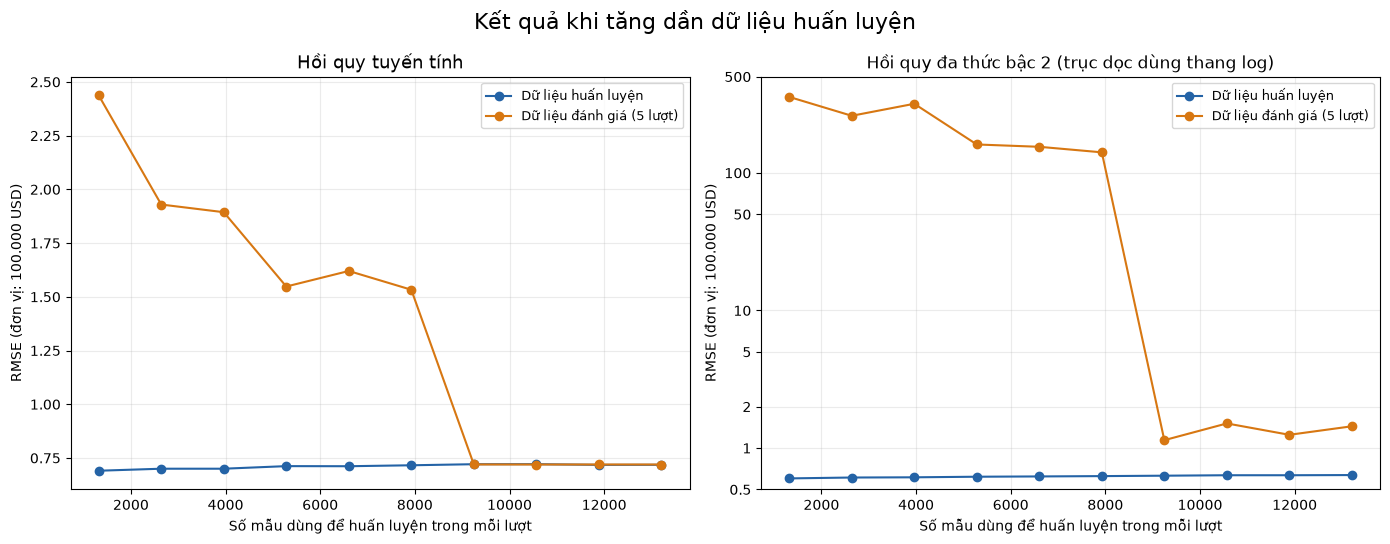

: 

: 

In [ ]:
from matplotlib.ticker import FuncFormatter

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, result) in zip(axes, learning_curve_results.items()):
    ax.plot(
        result["sizes"], result["train_rmse"],
        marker="o", color="#2463A6", label="Dữ liệu huấn luyện"
    )
    ax.plot(
        result["sizes"], result["validation_rmse"],
        marker="o", color="#D77712", label="Dữ liệu đánh giá (5 lượt)"
    )
    ax.set_title(name, fontsize=13)
    ax.set_xlabel("Số mẫu dùng để huấn luyện trong mỗi lượt")
    ax.set_ylabel("RMSE (đơn vị: 100.000 USD)")
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=9)

# Giữ đầy đủ các điểm sai lệch lớn, dùng thang log để đọc được cả hai đường
axes[1].set_yscale("log")
axes[1].set_ylim(0.5, 500)
axes[1].set_yticks([0.5, 1, 2, 5, 10, 50, 100, 500])
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
axes[1].minorticks_off()
axes[1].set_title("Hồi quy đa thức bậc 2 (trục dọc dùng thang log)", fontsize=12)

fig.suptitle("Kết quả khi tăng dần dữ liệu huấn luyện", fontsize=16)
fig.tight_layout()
fig.savefig("learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()


### Nhận xét kết quả 4.2

**Trên tập test để riêng từ 3.1:** Hồi quy đa thức bậc 2 có RMSE khoảng **0.6615**, thấp hơn mức **0.7092** của hồi quy tuyến tính. MAE giảm từ khoảng **52.003 USD** xuống **45.666 USD**, và R² tăng từ **0.6141** lên **0.6642**. Với lần chia train/test này, mô hình đa thức dự đoán tốt hơn.

**Hồi quy tuyến tính trên biểu đồ học:** Khi có nhiều dữ liệu, hai đường gần nhau và dừng quanh RMSE **0.72**. Thêm dữ liệu ở các mức cuối không giúp giảm sai lệch nhiều. Điều này gợi ý cách tính còn đơn giản, chưa học hết mối liên hệ trong dữ liệu; đề gọi là **bias cao / underfitting**.

**Hồi quy đa thức trên biểu đồ học:** Đường huấn luyện thấp hơn mô hình tuyến tính, nhưng đường đánh giá cao và dao động mạnh. Ở mức dữ liệu lớn nhất, RMSE huấn luyện khoảng **0.64**, còn RMSE đánh giá trung bình khoảng **1.44**. Mô hình làm tốt dữ liệu đã học nhưng kết quả kém ổn định khi đổi phần dữ liệu đánh giá; đây là dấu hiệu **variance cao / overfitting**.

Như vậy, đa thức tốt hơn trên tập test hiện tại nhưng chưa ổn định qua 5 lượt đánh giá. Thêm dữ liệu giúp giảm sai lệch lớn lúc đầu, nhưng chưa xóa được khoảng cách giữa hai đường. Phần 4.3 sẽ thử Ridge và Lasso để hạn chế việc mô hình phụ thuộc quá nhiều vào dữ liệu đã học.


## 4.3 Ridge, Lasso và lựa chọn thiết lập phù hợp

### Bước 1: Thử Ridge và Lasso với thiết lập mặc định

Ridge và Lasso cũng dùng thu nhập, tuổi nhà, số phòng… để đoán giá nhà. Hai mô hình này hạn chế mức ảnh hưởng của các thông tin đầu vào, giúp giảm nguy cơ học quá sát dữ liệu cũ. Lasso còn có thể bỏ hẳn một số thông tin khỏi cách tính.

Ở bước này, ta dùng `Ridge()` và `Lasso()` với thiết lập có sẵn, cho học từ tập huấn luyện rồi chấm kết quả. **RMSE, MAE càng thấp càng tốt; R² càng gần 1 càng tốt.**


In [ ]:
from sklearn.linear_model import Ridge, Lasso

# Tạo hai mô hình với thiết lập mặc định
ridge = Ridge()
lasso = Lasso()

# Cho học từ thông tin khu vực và giá nhà thật
ridge.fit(X_train_prepared, y_train)
lasso.fit(X_train_prepared, y_train)

# Chấm trên cả tập huấn luyện và tập kiểm tra
ridge_scores = evaluate_model(
    ridge, X_train_prepared, y_train,
    X_test_prepared, y_test, "Ridge (mặc định)"
)
print()
lasso_scores = evaluate_model(
    lasso, X_train_prepared, y_train,
    X_test_prepared, y_test, "Lasso"
)

# Gom kết quả để dễ so sánh, đánh số từ 1
results_4_3_default = pd.DataFrame([ridge_scores, lasso_scores])
results_4_3_default.index = range(1, len(results_4_3_default) + 1)
results_4_3_default.round(4)


Ridge (mặc định)
Train RMSE (RMSE tập học): 0.7184
Test RMSE (RMSE tập kiểm tra): 0.7092
Train MAE (Sai lệch trung bình tập học): 0.5252
Test MAE (Sai lệch trung bình tập kiểm tra): 0.52
Train R² (Điểm R² tập học): 0.6145
Test R² (Điểm R² tập kiểm tra): 0.6141

Lasso
Train RMSE (RMSE tập học): 1.157
Test RMSE (RMSE tập kiểm tra): 1.142
Train MAE (Sai lệch trung bình tập học): 0.913
Test MAE (Sai lệch trung bình tập kiểm tra): 0.9081
Train R² (Điểm R² tập học): 0
Test R² (Điểm R² tập kiểm tra): -4.288e-05


,Model,Train RMSE (RMSE tập học),Test RMSE (RMSE tập kiểm tra),Train MAE (Sai lệch trung bình tập học),Test MAE (Sai lệch trung bình tập kiểm tra),Train R² (Điểm R² tập học),Test R² (Điểm R² tập kiểm tra)
1,Ridge (mặc định),0.7184,0.7092,0.5252,0.5200,0.6145,0.6141
2,Lasso,1.1570,1.1417,0.9130,0.9081,0.0000,-0.0000


: 

: 

**Nhận xét:** Trên tập kiểm tra, Ridge (Test MAE) đoán lệch trung bình khoảng **52.002 USD**, còn Lasso (Test MAE) khoảng **90.807 USD**. Với thiết lập mặc định, **Ridge cho kết quả tốt hơn Lasso**: sai lệch thấp hơn và điểm R² cao hơn.

Bước tiếp theo của 4.3 là thử các giá trị `alpha` để chọn thiết lập phù hợp cho Ridge.


### Bước 2: Chọn alpha phù hợp cho Ridge

`alpha` giống một nút điều chỉnh mức hạn chế ảnh hưởng của các thông tin đầu vào. Ta thử **0.01, 0.1, 1, 10 và 100** theo đề.

`GridSearchCV` tự thử từng giá trị qua **5 lượt đánh giá**, rồi chọn giá trị có **RMSE trung bình thấp nhất**. Việc lựa chọn chỉ dùng dữ liệu huấn luyện; tập kiểm tra được dùng để chấm mô hình sau khi chọn xong.


In [ ]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV

# Ghép xử lý dữ liệu và Ridge để mỗi lượt chỉ học từ phần huấn luyện của lượt đó
ridge_search_pipeline = Pipeline([
    ("preprocessing", clone(num_pipeline)),
    ("ridge", Ridge())
])

# ridge__alpha là alpha của bước Ridge trong Pipeline
param_grid = {"ridge__alpha": [0.01, 0.1, 1, 10, 100]}
grid_search = GridSearchCV(
    ridge_search_pipeline,
    param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    error_score="raise"
)
# Dùng X_train vì Pipeline đã bao gồm bước xử lý dữ liệu
# GridSearchCV tự cho mô hình tốt nhất học lại trên toàn bộ tập train
grid_search.fit(X_train, y_train)

best_alpha = grid_search.best_params_["ridge__alpha"]
print("Alpha được chọn:", best_alpha)
print(f"RMSE đánh giá trung bình: {-grid_search.best_score_:.4f}")

# Đổi dấu vì scikit-learn trả về điểm RMSE âm
alpha_results = pd.DataFrame({
    "Alpha": grid_search.cv_results_["param_ridge__alpha"].astype(float),
    "RMSE trung bình qua 5 lượt": -grid_search.cv_results_["mean_test_score"],
    "Được chọn": [
        value == best_alpha
        for value in grid_search.cv_results_["param_ridge__alpha"]
    ]
})
alpha_results.index = range(1, len(alpha_results) + 1)
alpha_results.round(4)


Alpha được chọn: 10
RMSE đánh giá trung bình: 0.7197


,Alpha,RMSE trung bình qua 5 lượt,Được chọn
1,0.01,0.7197,False
2,0.10,0.7197,False
3,1.00,0.7197,False
4,10.00,0.7197,True
5,100.00,0.7203,False


: 

: 

### Bước 3: Chấm Ridge sau khi chọn alpha

Lấy mô hình vừa được chọn để đoán giá và so sánh với giá thật. Mô hình này đã có sẵn bước xử lý dữ liệu, nên đưa `X_train` và `X_test` vào trực tiếp.


In [ ]:
best_ridge = grid_search.best_estimator_
best_ridge_scores = evaluate_model(
    best_ridge, X_train, y_train,
    X_test, y_test, "Ridge"
)


Ridge
Train RMSE (RMSE tập học): 0.7184
Test RMSE (RMSE tập kiểm tra): 0.7092
Train MAE (Sai lệch trung bình tập học): 0.5251
Test MAE (Sai lệch trung bình tập kiểm tra): 0.52
Train R² (Điểm R² tập học): 0.6144
Test R² (Điểm R² tập kiểm tra): 0.6141


: 

: 

### Bước 4: So sánh các mô hình ở Part 4

Bảng dưới đây gom kết quả của 5 mô hình. **Train** là tập huấn luyện, **Test** là tập kiểm tra. RMSE và MAE càng thấp càng tốt; R² càng gần 1 càng tốt. RMSE và MAE trong bảng vẫn dùng đơn vị 100.000 USD.


In [ ]:
# Bảng tổng hợp theo yêu cầu của đề, có thêm MAE
regression_results = pd.DataFrame([
    lr_scores, sgd_scores, poly_scores, best_ridge_scores, lasso_scores
])
regression_results.index = range(1, len(regression_results) + 1)

# Giữ bảng số ở regression_results; chỉ định dạng bảng hiển thị
regression_preview = regression_results.copy()
for col in regression_preview.columns:
    if col != "Model":
        regression_preview[col] = regression_preview[col].map(
            lambda value: f"{value:.4g}"
        )
regression_preview


,Model,Train RMSE (RMSE tập học),Test RMSE (RMSE tập kiểm tra),Train MAE (Sai lệch trung bình tập học),Test MAE (Sai lệch trung bình tập kiểm tra),Train R² (Điểm R² tập học),Test R² (Điểm R² tập kiểm tra)
1,Linear Regression,0.7184,0.7092,0.5252,0.52,0.6145,0.6141
2,SGD Regressor,7.071e+07,9.569e+06,4.39e+06,3.625e+06,-3.735e+15,-7.026e+13
3,Polynomial Regression (bậc 2),0.6395,0.6615,0.4551,0.4567,0.6945,0.6642
4,Ridge,0.7184,0.7092,0.5251,0.52,0.6144,0.6141
5,Lasso,1.157,1.142,0.913,0.9081,0,-4.288e-05


: 

: 

### Nhận xét kết quả 4.3

**Ridge chọn alpha = 10**, vì giá trị này có RMSE trung bình thấp nhất qua 5 lượt đánh giá. Trên tập kiểm tra, Ridge đạt RMSE **0.7092** và R² **0.6141**; kết quả gần với hồi quy tuyến tính.

**Hồi quy đa thức bậc 2 tốt nhất trên tập kiểm tra hiện tại:** RMSE thấp nhất (**0.6615**), MAE thấp nhất (trung bình lệch khoảng **45,666 USD**) và R² cao nhất (**0.6642**). Vì vậy, xét bảng này, mô hình đa thức dự đoán giá sát hơn các mô hình còn lại.

Tuy vậy, biểu đồ ở 4.2 cho thấy mô hình đa thức còn dao động khi đổi dữ liệu đánh giá. Kết luận ở đây áp dụng cho tập kiểm tra hiện tại. Ridge ổn định hơn qua các lượt đánh giá đã chạy, nhưng chưa vượt đa thức trên tập kiểm tra này. SGD và Lasso với thiết lập đã dùng cho kết quả kém hơn.


# PART 5 — Classification Models (Các mô hình phân loại)

### Bước 1: Chia giá nhà thành hai nhóm

Ở phần này, máy sẽ đoán nhà thuộc **nhóm giá cao hay giá thấp**, theo mốc đề cho:

- **Nhãn 1:** giá cao từ **250.000 USD** trở lên.
- **Nhãn 0:** giá thấp dưới **250.000 USD**.

Trong dữ liệu, giá tính theo đơn vị 100.000 USD nên dùng mốc **2.5**. `y_train_bin` và `y_test_bin` là đáp án mới dạng 0 hoặc 1, tạo từ giá nhà thật. Mỗi mẫu tương ứng với một khu vực và dùng giá nhà median của khu vực đó.


In [ ]:
# Đổi giá nhà thành nhãn: 1 = giá cao, 0 = giá thấp
y_train_bin = (y_train >= 2.5).astype(int)
y_test_bin = (y_test >= 2.5).astype(int)

# Xem 5 mẫu đầu để thấy giá nhà được đổi thành nhóm nào
label_preview = pd.DataFrame({
    "Giá nhà (USD)": (y_train.head() * 100000).round(0),
    "Nhãn": y_train_bin.head(),
    "Nhóm": y_train_bin.head().map({0: "Giá thấp", 1: "Giá cao"})
})
label_preview.index = range(1, len(label_preview) + 1)
label_preview


,Giá nhà (USD),Nhãn,Nhóm
1,72100.0,0,Giá thấp
2,279600.0,1,Giá cao
3,82700.0,0,Giá thấp
4,112500.0,0,Giá thấp
5,238300.0,0,Giá thấp


: 

: 

### Bước 2: Đếm tỷ lệ hai nhóm

Đếm xem trong tập huấn luyện có bao nhiêu mẫu **giá thấp** và **giá cao**. `value_counts(normalize=True)` tính tỷ lệ của từng nhóm; nhân với 100 để đổi sang phần trăm.


In [ ]:
# Đếm số mẫu và tính tỷ lệ của từng nhóm trong tập huấn luyện
class_counts = y_train_bin.value_counts().reindex([0, 1], fill_value=0)
class_proportions = y_train_bin.value_counts(normalize=True).reindex([0, 1], fill_value=0)

class_distribution = pd.DataFrame({
    "Nhóm": ["Giá thấp (0)", "Giá cao (1)"],
    "Số mẫu": class_counts.to_numpy(),
    "Tỷ lệ (%)": (class_proportions * 100).to_numpy()
})
class_distribution.index = range(1, len(class_distribution) + 1)
class_distribution.round(2)


,Nhóm,Số mẫu,Tỷ lệ (%)
1,Giá thấp (0),11877,71.93
2,Giá cao (1),4635,28.07


: 

: 

**Hai nhóm có cân bằng không?** Nhóm giá thấp chiếm **71,93%**, còn nhóm giá cao chiếm **28,07%**. Nhóm giá thấp đông hơn, nên dữ liệu có sự chênh lệch giữa hai nhóm (class imbalance).

**Vì sao không chỉ nhìn accuracy — tỷ lệ đoán đúng?** Giả sử máy luôn đoán “giá thấp” cho mọi mẫu trong tập huấn luyện, nó vẫn đúng **71,93%** vì nhóm này chiếm **71,93%** dữ liệu. Nhưng máy không nhận ra mẫu giá cao nào. Vì vậy, chỉ nhìn accuracy thì chưa đủ để đánh giá mô hình.

Vì vậy, ngoài accuracy, cần xem thêm **precision** (trong những mẫu máy đoán là giá cao, bao nhiêu mẫu đúng), **recall** (trong những mẫu thật sự giá cao, máy tìm được bao nhiêu) và **AUC-ROC** (khả năng phân biệt hai nhóm). Các điểm này sẽ được tính ở những bước tiếp theo.


## 5.1 K-Nearest Neighbors (KNN) và Naive Bayes

### Bước 1: Cho hai mô hình học

- **KNN với k = 5:** xem 5 mẫu gần giống nhất trong tập huấn luyện. Nhóm nào nhiều hơn thì chọn nhóm đó.
- **Gaussian Naive Bayes:** học đặc điểm của nhóm giá thấp và giá cao, rồi tính xem một mẫu có khả năng thuộc nhóm nào hơn. Mô hình tính đơn giản bằng cách coi các thông tin đầu vào là độc lập với nhau trong từng nhóm.

Hai mô hình cùng học từ `X_train_prepared` và đáp án `y_train_bin`, sau đó đoán nhóm cho các mẫu trong tập kiểm tra.


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# KNN: xem 5 mẫu gần giống nhất
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_prepared, y_train_bin)

# Naive Bayes: học đặc điểm của từng nhóm
gnb = GaussianNB()
gnb.fit(X_train_prepared, y_train_bin)
print("Đã huấn luyện KNN (k=5) và Gaussian Naive Bayes.")


Đã huấn luyện KNN (k=5) và Gaussian Naive Bayes.


: 

: 

### Bước 2: Chấm kết quả trên tập kiểm tra

- **Accuracy:** tỷ lệ đoán đúng trong tất cả các mẫu.
- **Precision:** trong những mẫu máy đoán là giá cao, bao nhiêu mẫu đúng?
- **Recall:** trong những mẫu thật sự giá cao, máy tìm được bao nhiêu?
- **F1:** điểm kết hợp precision và recall; càng gần 1 càng tốt.
- **AUC-ROC:** khả năng phân biệt hai nhóm dựa trên điểm dự đoán; càng gần 1 càng tốt, khoảng 0.5 tương đương xếp hạng ngẫu nhiên.

Báo cáo riêng từng nhóm bên dưới tính precision, recall và F1 cho nhóm được ghi ở mỗi dòng. **Số mẫu** là số đáp án thật của nhóm đó. Bảng đếm đúng/sai có **hàng là giá thật, cột là giá máy đoán**; hai ô trên đường chéo là số mẫu đoán đúng.


In [ ]:
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    accuracy_score, precision_score, recall_score, f1_score
)


def evaluate_classifier(model, X_te, y_te, name):
    # Lấy nhóm dự đoán và điểm khả năng thuộc nhóm giá cao
    y_pred = model.predict(X_te)
    high_price_column = list(model.classes_).index(1)
    y_probability = model.predict_proba(X_te)[:, high_price_column]

    report = classification_report(
        y_te, y_pred, labels=[0, 1],
        target_names=["Giá thấp (0)", "Giá cao (1)"],
        output_dict=True, zero_division=0
    )
    report_table = pd.DataFrame(report).T.loc[["Giá thấp (0)", "Giá cao (1)"]]
    report_table = report_table.rename(columns={
        "precision": "Precision", "recall": "Recall",
        "f1-score": "F1", "support": "Số mẫu"
    })
    report_table["Số mẫu"] = report_table["Số mẫu"].astype(int)

    print(name)
    print(report_table.to_string(float_format=lambda value: f"{value:.3f}"))
    print("\nBảng đếm đúng/sai (hàng: giá thật, cột: dự đoán):")
    counts = pd.DataFrame(
        confusion_matrix(y_te, y_pred, labels=[0, 1]),
        index=["Thật: giá thấp", "Thật: giá cao"],
        columns=["Đoán: giá thấp", "Đoán: giá cao"]
    )
    print(counts.to_string())

    # Trong bảng tổng hợp, precision/recall/F1 tính cho nhóm giá cao (1)
    scores = {
        "Mô hình": name,
        "Accuracy (%)": accuracy_score(y_te, y_pred) * 100,
        "Precision (%)": precision_score(y_te, y_pred, pos_label=1, zero_division=0) * 100,
        "Recall (%)": recall_score(y_te, y_pred, pos_label=1, zero_division=0) * 100,
        "F1": f1_score(y_te, y_pred, pos_label=1, zero_division=0),
        "AUC-ROC": roc_auc_score(y_te, y_probability)
    }
    print(f"\nAccuracy: {scores['Accuracy (%)']:.2f}% | AUC-ROC: {scores['AUC-ROC']:.4f}\n")
    return scores


knn_scores = evaluate_classifier(knn, X_test_prepared, y_test_bin, "KNN (k=5)")
gnb_scores = evaluate_classifier(gnb, X_test_prepared, y_test_bin, "Naive Bayes")


KNN (k=5)
              Precision  Recall    F1  Số mẫu
Giá thấp (0)      0.873   0.933 0.902    2934
Giá cao (1)       0.802   0.665 0.727    1194

Bảng đếm đúng/sai (hàng: giá thật, cột: dự đoán):
                Đoán: giá thấp  Đoán: giá cao
Thật: giá thấp            2738            196
Thật: giá cao              400            794

Accuracy: 85.56% | AUC-ROC: 0.8891

Naive Bayes
              Precision  Recall    F1  Số mẫu
Giá thấp (0)      0.862   0.822 0.842    2934
Giá cao (1)       0.608   0.677 0.641    1194

Bảng đếm đúng/sai (hàng: giá thật, cột: dự đoán):
                Đoán: giá thấp  Đoán: giá cao
Thật: giá thấp            2413            521
Thật: giá cao              386            808

Accuracy: 78.03% | AUC-ROC: 0.8112



: 

: 

### Bước 3: Thử k từ 1 đến 20

Đề yêu cầu thử số láng giềng từ **1 đến 20** bằng đánh giá chéo. Ở đây chọn **5 lượt**: chia tập huấn luyện thành 5 phần, luân phiên dùng 4 phần để học và 1 phần để đánh giá.

Chọn `k` có **accuracy trung bình cao nhất**. Chỉ dùng dữ liệu huấn luyện để chọn `k`; tập kiểm tra được chấm sau khi chọn xong. Nếu nhiều giá trị có cùng điểm cao nhất, chọn giá trị nhỏ nhất trong số đó.


In [ ]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Tính lại bước xử lý từ phần huấn luyện của từng lượt
knn_search_pipeline = Pipeline([
    ("preprocessing", clone(num_pipeline)),
    ("knn", KNeighborsClassifier())
])
# Giữ tỷ lệ hai nhóm gần giống nhau trong mỗi phần
knn_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
knn_search = GridSearchCV(
    knn_search_pipeline,
    {"knn__n_neighbors": list(range(1, 21))},
    cv=knn_cv,
    scoring="accuracy",
    n_jobs=1,
    error_score="raise"
)
knn_search.fit(X_train, y_train_bin)

best_k = knn_search.best_params_["knn__n_neighbors"]
k_results = pd.DataFrame({
    "k (số láng giềng)": knn_search.cv_results_["param_knn__n_neighbors"].astype(int),
    "Accuracy trung bình (%)": knn_search.cv_results_["mean_test_score"] * 100
})
k_results.index = range(1, len(k_results) + 1)
print("k được chọn:", best_k)
print(f"Accuracy trung bình qua 5 lượt: {knn_search.best_score_ * 100:.2f}%")
k_results.round(2)


k được chọn: 10
Accuracy trung bình qua 5 lượt: 85.18%


,k (số láng giềng),Accuracy trung bình (%)
1,1,82.38
2,2,83.21
3,3,83.95
4,4,84.37
5,5,84.57
6,6,84.71
7,7,84.97
8,8,84.71
9,9,85.04
10,10,85.18


: 

: 

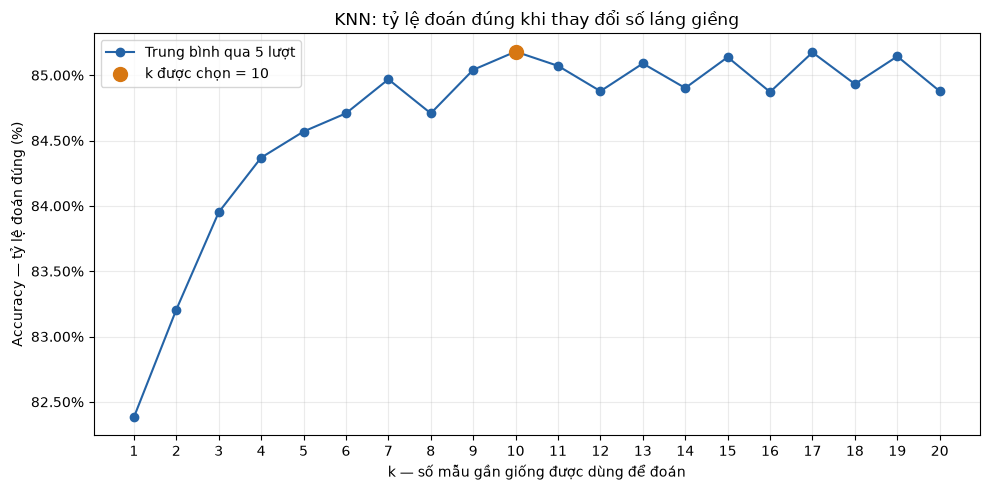

: 

: 

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    k_results["k (số láng giềng)"], k_results["Accuracy trung bình (%)"],
    marker="o", color="#2463A6", label="Trung bình qua 5 lượt"
)
ax.scatter(
    best_k, knn_search.best_score_ * 100,
    s=100, color="#D77712", zorder=3, label=f"k được chọn = {best_k}"
)
ax.set_title("KNN: tỷ lệ đoán đúng khi thay đổi số láng giềng")
ax.set_xlabel("k — số mẫu gần giống được dùng để đoán")
ax.set_ylabel("Accuracy — tỷ lệ đoán đúng (%)")
ax.set_xticks(range(1, 21))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig("knn_accuracy_vs_k.png", dpi=150, bbox_inches="tight")
plt.show()


### Bước 4: Chấm KNN sau khi chọn k và so sánh

`GridSearchCV` đã cho KNN với `k` được chọn học lại trên toàn bộ tập huấn luyện. Mô hình này có sẵn bước xử lý dữ liệu nên nhận `X_test` trực tiếp.

Bảng tổng hợp chấm trên cùng tập kiểm tra. Accuracy, precision và recall được ghi theo phần trăm; F1 và AUC-ROC nằm trong khoảng 0 đến 1. Precision, recall và F1 ở bảng này tính cho **nhóm giá cao**.


In [ ]:
best_knn = knn_search.best_estimator_
best_knn_scores = evaluate_classifier(
    best_knn, X_test, y_test_bin, f"KNN (k={best_k}, được chọn)"
)

classifier_results_5_1 = pd.DataFrame([
    knn_scores, best_knn_scores, gnb_scores
])
classifier_results_5_1.index = range(1, len(classifier_results_5_1) + 1)
classifier_results_5_1.round(3)


KNN (k=10, được chọn)
              Precision  Recall    F1  Số mẫu
Giá thấp (0)      0.854   0.954 0.901    2934
Giá cao (1)       0.841   0.600 0.700    1194

Bảng đếm đúng/sai (hàng: giá thật, cột: dự đoán):
                Đoán: giá thấp  Đoán: giá cao
Thật: giá thấp            2799            135
Thật: giá cao              478            716

Accuracy: 85.15% | AUC-ROC: 0.9094



,Mô hình,Accuracy (%),Precision (%),Recall (%),F1,AUC-ROC
1,KNN (k=5),85.562,80.202,66.499,0.727,0.889
2,"KNN (k=10, được chọn)",85.150,84.136,59.966,0.700,0.909
3,Naive Bayes,78.028,60.798,67.672,0.641,0.811


: 

: 

### Nhận xét kết quả 5.1

**KNN chọn k = 10**, vì có tỷ lệ đoán đúng trung bình cao nhất qua 5 lượt: **85,18%**. Biểu đồ cho thấy tăng k không phải lúc nào cũng làm kết quả tốt hơn.

Trên tập kiểm tra, **KNN (k=5)** đoán đúng **85,56%**, **KNN với k được chọn** đúng **85,15%**, còn **Naive Bayes** đúng **78,03%**.

Với nhóm giá cao, KNN(k = 10) được chọn tìm được **59,97%** số mẫu thật sự giá cao; Naive Bayes tìm được **67,67%**. AUC-ROC lần lượt là **0.9094** và **0.8112**. Cần xem các điểm này cùng tỷ lệ đoán đúng để biết mô hình nhận ra nhóm giá cao tốt đến đâu.

**KNN với k được chọn cho kết quả tốt hơn Naive Bayes trên tập kiểm tra này** về tỷ lệ đoán đúng và AUC-ROC.

**KNN k=5 vẫn có tỷ lệ đoán đúng trên tập test cao hơn k=10 một chút.** Ta chọn k=10 theo kết quả đánh giá chéo trên tập huấn luyện; kết quả tốt nhất ở đó không bảo đảm cũng cao nhất trên tập test. Naive Bayes tìm được nhiều mẫu giá cao hơn theo recall, nhưng cũng có nhiều lần báo nhầm là giá cao hơn, thể hiện qua precision thấp hơn.


## 5.2 Decision Trees & Random Forests (Cây quyết định và Rừng ngẫu nhiên)

### Bước 1: Huấn luyện cây quyết định và in cấu trúc cây

Huấn luyện `DecisionTreeClassifier` với `max_depth=5`, sau đó dùng `export_text()` để in cấu trúc cây theo đề.

**Cách đọc output:** Mỗi mức thụt vào là một tầng của cây. `<=` nghĩa là nhỏ hơn hoặc bằng, `>` nghĩa là lớn hơn. Đi theo các điều kiện đến `class: 0` (giá thấp) hoặc `class: 1` (giá cao). Các mốc chia dùng dữ liệu đã chuẩn hóa ở mục 3.3.


In [42]:
from sklearn.tree import DecisionTreeClassifier, export_text

# Huấn luyện cây quyết định với độ sâu tối đa 5
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train_prepared, y_train_bin)

# In cấu trúc cây dạng chữ theo yêu cầu của đề
print(export_text(dt, feature_names=feature_cols))


|--- MedInc <= 0.90
|   |--- AveOccup <= -0.06
|   |   |--- MedInc <= -0.39
|   |   |   |--- Latitude <= 1.06
|   |   |   |   |--- Longitude <= -1.36
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- Longitude >  -1.36
|   |   |   |   |   |--- class: 0
|   |   |   |--- Latitude >  1.06
|   |   |   |   |--- bedrooms_ratio <= -0.56
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- bedrooms_ratio >  -0.56
|   |   |   |   |   |--- class: 0
|   |   |--- MedInc >  -0.39
|   |   |   |--- HouseAge <= -0.73
|   |   |   |   |--- MedInc <= 0.17
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- MedInc >  0.17
|   |   |   |   |   |--- class: 0
|   |   |   |--- HouseAge >  -0.73
|   |   |   |   |--- Latitude <= 1.10
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- Latitude >  1.10
|   |   |   |   |   |--- class: 0
|   |--- AveOccup >  -0.06
|   |   |--- MedInc <= 0.27
|   |   |   |--- Longitude <= -1.41
|   |   |   |   |--- Latitude <= 1.20
|   |   |   |   |   |--- class: 1
|   

### Bước 2: Cho rừng ngẫu nhiên học

Rừng ngẫu nhiên dùng nhiều cây cùng dự đoán và tổng hợp kết quả. Đề yêu cầu **100 cây**. Sau khi học, ta chấm hai mô hình trên cùng tập kiểm tra như ở 5.1.

Trong bảng đếm đúng/sai, chữ **“Thật:” ở mé trái** chỉ nhóm giá thật; chữ **“Đoán:” ở dòng trên cùng** chỉ nhóm máy dự đoán. Ở bảng tổng hợp, precision, recall và F1 tính cho nhóm giá cao.


In [43]:
from sklearn.ensemble import RandomForestClassifier

# Tạo rừng gồm 100 cây theo yêu cầu của đề
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_prepared, y_train_bin)

# Dùng lại hàm chấm ở 5.1
dt_scores = evaluate_classifier(dt, X_test_prepared, y_test_bin, "Cây quyết định")
rf_scores = evaluate_classifier(rf, X_test_prepared, y_test_bin, "Rừng ngẫu nhiên")

classifier_results_5_2 = pd.DataFrame([dt_scores, rf_scores])
classifier_results_5_2.index = range(1, len(classifier_results_5_2) + 1)
classifier_results_5_2.round(3)


Cây quyết định
              Precision  Recall    F1  Số mẫu
Giá thấp (0)      0.870   0.944 0.906    2934
Giá cao (1)       0.826   0.653 0.730    1194

Bảng đếm đúng/sai (hàng: giá thật, cột: dự đoán):
                Đoán: giá thấp  Đoán: giá cao
Thật: giá thấp            2770            164
Thật: giá cao              414            780

Accuracy: 86.00% | AUC-ROC: 0.8995

Rừng ngẫu nhiên
              Precision  Recall    F1  Số mẫu
Giá thấp (0)      0.908   0.956 0.931    2934
Giá cao (1)       0.876   0.761 0.815    1194

Bảng đếm đúng/sai (hàng: giá thật, cột: dự đoán):
                Đoán: giá thấp  Đoán: giá cao
Thật: giá thấp            2805            129
Thật: giá cao              285            909

Accuracy: 89.97% | AUC-ROC: 0.9557



,Mô hình,Accuracy (%),Precision (%),Recall (%),F1,AUC-ROC
1,Cây quyết định,85.998,82.627,65.327,0.730,0.899
2,Rừng ngẫu nhiên,89.971,87.572,76.131,0.815,0.956


### Bước 3: Xem rừng ngẫu nhiên dựa nhiều vào thông tin nào

Thanh càng dài thì thông tin đó đóng góp càng nhiều vào việc chia nhánh của các cây. Tổng các mức đóng góp là 100%; đây **không phải tỷ lệ dự đoán đúng**.


In [44]:
# Lấy mức độ quan trọng của 11 thông tin đầu vào
importances = pd.Series(
    rf.feature_importances_, index=feature_cols
).sort_values(ascending=False)

# Thêm tiếng Việt để dễ đọc biểu đồ
feature_labels = {
    "MedInc": "MedInc — Thu nhập",
    "HouseAge": "HouseAge — Tuổi nhà",
    "AveRooms": "AveRooms — Số phòng mỗi hộ",
    "AveBedrms": "AveBedrms — Số phòng ngủ mỗi hộ",
    "Population": "Population — Số dân khu vực",
    "AveOccup": "AveOccup — Số người mỗi hộ",
    "Latitude": "Latitude — Vĩ độ (vị trí Bắc–Nam)",
    "Longitude": "Longitude — Kinh độ (vị trí Đông–Tây)",
    "rooms_per_household": "rooms_per_household — Số phòng mỗi hộ",
    "bedrooms_ratio": "bedrooms_ratio — Tỷ lệ phòng ngủ",
    "population_per_household": "population_per_household — Số người mỗi hộ"
}

importance_table = pd.DataFrame({
    "Thông tin": [feature_labels[name] for name in importances.index],
    "Mức đóng góp (%)": importances.to_numpy() * 100
})
importance_table.index = range(1, len(importance_table) + 1)
importance_table.round(2)


,Thông tin,Mức đóng góp (%)
1,MedInc — Thu nhập,26.69
2,Longitude — Kinh độ (vị trí Đông–Tây),10.99
3,Latitude — Vĩ độ (vị trí Bắc–Nam),10.74
4,bedrooms_ratio — Tỷ lệ phòng ngủ,9.30
5,AveOccup — Số người mỗi hộ,8.29
6,population_per_household — Số người mỗi hộ,8.13
7,rooms_per_household — Số phòng mỗi hộ,6.12
8,AveRooms — Số phòng mỗi hộ,5.77
9,HouseAge — Tuổi nhà,5.56
10,Population — Số dân khu vực,4.25


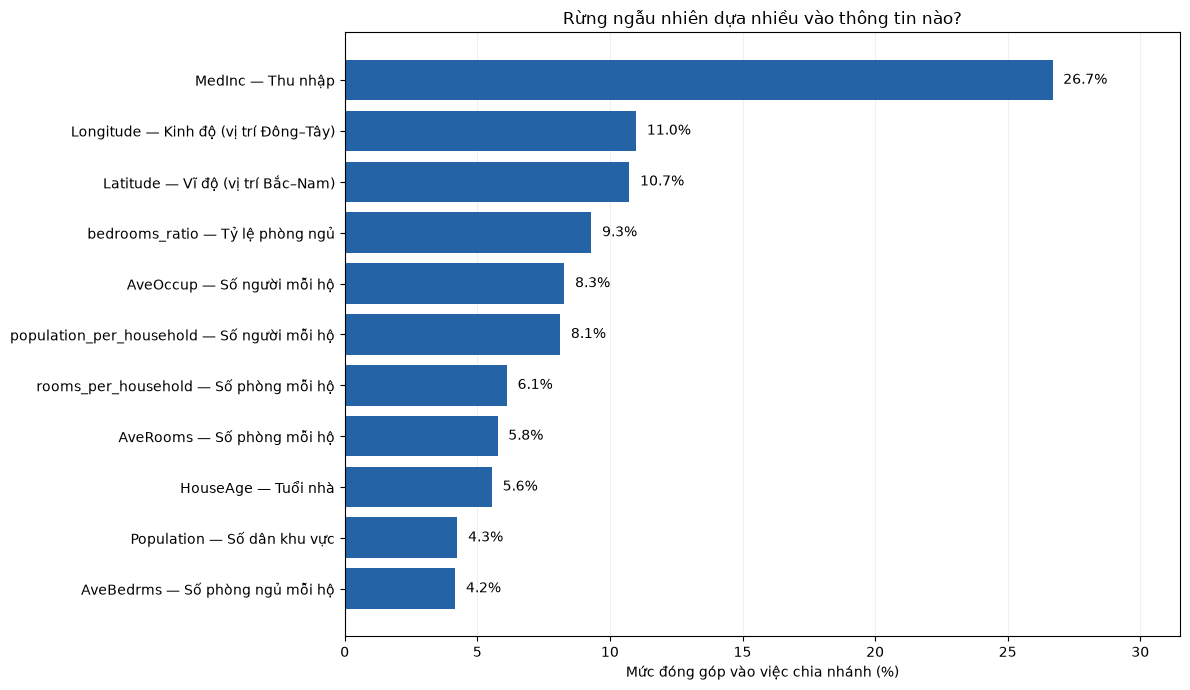

: 

: 

In [ ]:
fig, ax = plt.subplots(figsize=(12, 7))
values = importances * 100
positions = np.arange(len(values))
ax.barh(positions, values.to_numpy(), color="#2463A6")
ax.set_yticks(positions, [feature_labels[name] for name in values.index])
ax.invert_yaxis()
ax.set_xlabel("Mức đóng góp vào việc chia nhánh (%)")
ax.set_title("Rừng ngẫu nhiên dựa nhiều vào thông tin nào?")
ax.set_xlim(0, values.max() * 1.18)
for position, value in enumerate(values):
    ax.text(value + values.max() * 0.015, position, f"{value:.1f}%", va="center")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig("rf_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()


### Nhận xét kết quả 5.2

**Thông tin quan trọng nhất:** Ba cột đứng đầu là **MedInc — Thu nhập (26.69%)**; **Longitude — Kinh độ (vị trí Đông–Tây) (10.99%)**; **Latitude — Vĩ độ (vị trí Bắc–Nam) (10.74%)**.

**So với Part 2:** Thu nhập (`MedInc`) vẫn đứng đầu, phù hợp với kết quả phân tích trước đó. Ở Part 2, ba cột có tương quan mạnh nhất với giá nhà là thu nhập, số phòng (`AveRooms`) và vĩ độ (`Latitude`). Thứ tự ở đây có thể khác vì rừng ngẫu nhiên kết hợp nhiều thông tin để chia nhóm giá cao/thấp, còn Part 2 xét mối liên hệ tuyến tính của từng cột với giá nhà.

Hai cặp cột `AveRooms` / `rooms_per_household` và `AveOccup` / `population_per_household` chứa cùng thông tin. Các cây có thể chọn cột này hoặc cột kia, nên mức đóng góp được chia cho cả hai cột.

**Kết quả kiểm tra:** Cây quyết định đoán đúng **86.00%**, rừng ngẫu nhiên đúng **89.97%**. Với nhóm giá cao, hai mô hình tìm được lần lượt **65.33%** và **76.13%** số mẫu thật sự giá cao. AUC-ROC lần lượt là **0.8995** và **0.9557**.

**Rừng ngẫu nhiên cho kết quả tốt hơn cây quyết định trên tập kiểm tra này** về tỷ lệ đoán đúng và AUC-ROC.


## 5.3 Support Vector Machines (SVM)

### Bước 1: Huấn luyện SVM với kernel RBF

SVM học cách phân biệt **giá thấp (0)** và **giá cao (1)**. Kernel **RBF** cho phép tạo ranh giới phân loại phi tuyến, có thể uốn cong theo dữ liệu.

Dùng đúng các tham số trong đề và toàn bộ tập huấn luyện đã chuẩn hóa. `probability=True` cho phép lấy xác suất dự đoán để tính AUC-ROC. Thời gian huấn luyện được đo để nhận xét chi phí tính toán; con số này phụ thuộc vào máy và các chương trình đang chạy.


In [45]:
from sklearn.svm import SVC
from time import perf_counter

svm_rbf = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42)
start = perf_counter()
svm_rbf.fit(X_train_prepared, y_train_bin)
svm_rbf_fit_seconds = perf_counter() - start

print(f"Đã huấn luyện SVM RBF trên {len(y_train_bin):,} mẫu.")
print(f"Thời gian huấn luyện: {svm_rbf_fit_seconds:.2f} giây.")


d:\ProjectML\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Đã huấn luyện SVM RBF trên 16,512 mẫu.
Thời gian huấn luyện: 21.87 giây.


### Bước 2: Huấn luyện SVM với kernel Linear

Kernel **Linear** dùng ranh giới phân loại tuyến tính. Cho mô hình học trên cùng dữ liệu với SVM RBF để so sánh kết quả.


In [46]:
svm_lin = SVC(kernel='linear', C=1.0, probability=True, random_state=42)
start = perf_counter()
svm_lin.fit(X_train_prepared, y_train_bin)
svm_lin_fit_seconds = perf_counter() - start

print(f"Đã huấn luyện SVM Linear trên {len(y_train_bin):,} mẫu.")
print(f"Thời gian huấn luyện: {svm_lin_fit_seconds:.2f} giây.")


d:\ProjectML\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Đã huấn luyện SVM Linear trên 16,512 mẫu.
Thời gian huấn luyện: 18.92 giây.


### Bước 3: Chấm kết quả và so sánh AUC-ROC

Dùng lại hàm đánh giá ở mục 5.1 để chấm hai SVM trên cùng tập kiểm tra. **AUC-ROC càng lớn thì khả năng phân biệt hai nhóm càng tốt**. Accuracy, precision và recall được ghi theo phần trăm; precision và recall tính cho **nhóm giá cao (1)**.


In [47]:
svm_rbf_scores = evaluate_classifier(svm_rbf, X_test_prepared, y_test_bin, "SVM (RBF)")
svm_lin_scores = evaluate_classifier(svm_lin, X_test_prepared, y_test_bin, "SVM (Linear)")

svm_results = pd.DataFrame([svm_rbf_scores, svm_lin_scores])[
    ["Mô hình", "Accuracy (%)", "Precision (%)", "Recall (%)", "AUC-ROC"]
]
svm_results.index = range(1, len(svm_results) + 1)
svm_results.round(4)


SVM (RBF)
              Precision  Recall    F1  Số mẫu
Giá thấp (0)      0.883   0.954 0.917    2934
Giá cao (1)       0.858   0.691 0.766    1194

Bảng đếm đúng/sai (hàng: giá thật, cột: dự đoán):
                Đoán: giá thấp  Đoán: giá cao
Thật: giá thấp            2798            136
Thật: giá cao              369            825

Accuracy: 87.77% | AUC-ROC: 0.9373

SVM (Linear)
              Precision  Recall    F1  Số mẫu
Giá thấp (0)      0.878   0.939 0.908    2934
Giá cao (1)       0.820   0.679 0.743    1194

Bảng đếm đúng/sai (hàng: giá thật, cột: dự đoán):
                Đoán: giá thấp  Đoán: giá cao
Thật: giá thấp            2756            178
Thật: giá cao              383            811

Accuracy: 86.41% | AUC-ROC: 0.9260



,Mô hình,Accuracy (%),Precision (%),Recall (%),AUC-ROC
1,SVM (RBF),87.7665,85.8481,69.0955,0.9373
2,SVM (Linear),86.4099,82.0020,67.9229,0.9260


### Nhận xét hai kernel

**SVM RBF** đạt accuracy **87.77%**, AUC-ROC **0.9373**; **SVM Linear** đạt accuracy **86.41%**, AUC-ROC **0.9260**. **SVM RBF phân biệt hai nhóm tốt hơn theo AUC-ROC trên tập kiểm tra này.**

Trong lần chạy này, thời gian huấn luyện RBF là **24.54 giây**, Linear là **21.41 giây**. Cả hai đều dùng toàn bộ **16,512 mẫu huấn luyện** và bật `probability=True`. Đây là thời gian đo trên máy hiện tại, không phải mức cố định cho mọi máy hay mọi dữ liệu.


### Bước 4: Bảng so sánh các mô hình phân loại

Tổng hợp đủ **7 mô hình** và **4 chỉ số** theo đề. Tất cả được chấm trên cùng tập kiểm tra. KNN với `k` được chọn sử dụng kết quả đánh giá chéo ở 5.1. Precision và recall tính cho nhóm giá cao (1).


In [48]:
classifier_results = pd.DataFrame([
    knn_scores,
    best_knn_scores,
    gnb_scores,
    dt_scores,
    rf_scores,
    svm_rbf_scores,
    svm_lin_scores
])[["Mô hình", "Accuracy (%)", "Precision (%)", "Recall (%)", "AUC-ROC"]]
classifier_results.index = range(1, len(classifier_results) + 1)
classifier_results.round(4)


,Mô hình,Accuracy (%),Precision (%),Recall (%),AUC-ROC
1,KNN (k=5),85.5620,80.2020,66.4992,0.8891
2,"KNN (k=10, được chọn)",85.1502,84.1363,59.9665,0.9094
3,Naive Bayes,78.0281,60.7976,67.6717,0.8112
4,Cây quyết định,85.9981,82.6271,65.3266,0.8995
5,Rừng ngẫu nhiên,89.9709,87.5723,76.1307,0.9557
6,SVM (RBF),87.7665,85.8481,69.0955,0.9373
7,SVM (Linear),86.4099,82.0020,67.9229,0.9260


### Bước 5: Đề xuất mô hình sử dụng thực tế

**Ở đây nên dùng Random Forest với 100 cây cho bài toán này**, dựa trên kết quả của tập kiểm tra hiện tại:

- **Accuracy: 89.97%**, **precision: 87.57%**, **recall: 76.13%** và **AUC-ROC: 0.9557** — đều cao nhất trong 7 mô hình được so sánh.
- Với nhóm giá cao, recall cao hơn nghĩa là mô hình nhận ra được nhiều mẫu giá cao hơn; precision cao hơn nghĩa là ít báo nhầm giá thấp thành giá cao hơn trong các dự đoán giá cao.
- Về chi phí tính toán, rừng gồm 100 cây cần nhiều bộ nhớ và công tính toán hơn một cây quyết định đơn lẻ. Tuy nhiên, có thể huấn luyện các cây song song bằng `n_jobs=-1`; mức chi phí này là sự đánh đổi hợp lý để lấy kết quả tốt hơn trong bài lab.

SVM RBF là lựa chọn tiếp theo về accuracy và AUC-ROC, nhưng việc huấn luyện SVM với nhiều mẫu có thể tốn thời gian, đặc biệt khi bật tính xác suất. Trong lần chạy này, RBF mất **24.54 giây**, Linear mất **21.41 giây**; cả hai đều dùng đủ **16,512 mẫu huấn luyện**. KNN ít tốn công huấn luyện nhưng phải lưu dữ liệu và tìm các mẫu gần nhất khi dự đoán. Naive Bayes đơn giản hơn nhưng kết quả trong bảng thấp hơn đáng kể.

**Kết luận này là đề xuất từ bài lab.** Trước khi triển khai thực tế, cần đo thêm thời gian dự đoán và bộ nhớ của các mô hình trên hệ thống sử dụng; bài này chưa đo hai yếu tố đó nên chưa kết luận Random Forest là mô hình nhanh nhất hay tiết kiệm bộ nhớ nhất.


# PART 6 — Report & Interpretation
California Housing gồm 20.640 mẫu theo khu vực, 8 đặc trưng và không có giá trị thiếu. Giá nhà lệch phải, thu nhập liên hệ rõ với giá. Khó khăn gồm ngoại lệ, dữ liệu cũ và mất cân bằng nhãn: nhóm giá thấp chiếm 71,93% tập huấn luyện.

Chia phân tầng theo thu nhập giúp giữ tỷ lệ nhóm giữa train/test. StandardScaler đưa các cột về cùng thang đo, quan trọng với KNN và SVM; chỉ học thông số từ train để tránh rò rỉ dữ liệu. Chưa thử loại bỏ từng bước nên chưa xác định bước cải thiện nhiều nhất. SimpleImputer chưa thay giá trị nào; bedrooms_ratio bổ sung thông tin, còn hai đặc trưng mới khác trùng cột gốc.

Hồi quy đa thức bậc 2 tốt nhất trên tập test: RMSE 0,6615, R² 0,6642 và MAE khoảng 45.666 USD. Nghĩa là dự đoán giá nhà median của khu vực lệch tuyệt đối trung bình khoảng 45.666 USD. Tuy nhiên, đường cong học cho thấy kết quả chưa ổn định qua đánh giá chéo.

Random Forest tốt nhất trong các mô hình phân loại: accuracy 89,97%, precision 87,57%, recall 76,13% và AUC-ROC 0,9557. Mô hình phù hợp để phân biệt giá cao/thấp, nhưng vẫn bỏ sót một phần nhóm giá cao. Dùng 100 cây đòi hỏi cân nhắc bộ nhớ và thời gian dự đoán khi triển khai.

Hai hướng cải thiện: (1) dùng đánh giá chéo để chọn max_depth, min_samples_leaf và max_features của Random Forest; (2) thử Ridge sau bước tạo đặc trưng đa thức, chọn alpha bằng đánh giá chéo để giảm dao động. Mọi lựa chọn dùng dữ liệu huấn luyện; cần tập đánh giá độc lập khi xác nhận cải tiến.
